# Trabajo Práctico 3 (TP3): Clasificación de Imágenes de Cáncer de Mama usando PCA y SVD

## Objetivo
El objetivo de este Trabajo Práctico es aplicar los conceptos de reducción de dimensionalidad vistos en la Clase 8 (**SVD y PCA**) para construir un clasificador de imágenes médicas. 

Trabajaremos con imágenes de ultrasonido de mama para clasificarlas en **Benignas** o **Malignas**.

## 1. Obtención del Dataset (BreastMNIST)
Para este TP utilizaremos **BreastMNIST**, un subconjunto del famoso dataset MedMNIST, el cual contiene imágenes de ultrasonido de mama de 28x28 píxeles en escala de grises.

**Instrucciones:** Si no tienes instalada la librería `medmnist`, ejecuta la siguiente celda.

In [1]:
# !pip install medmnist

A continuación, descargaremos y cargaremos los datos de entrenamiento y prueba.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import medmnist
from medmnist import BreastMNIST

# Descargar y cargar los datos
train_dataset = BreastMNIST(split='train', download=True)
test_dataset = BreastMNIST(split='test', download=True)

# Extraer las imágenes y las etiquetas
X_train = train_dataset.imgs
y_train = train_dataset.labels.squeeze()

X_test = test_dataset.imgs
y_test = test_dataset.labels.squeeze()

print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de X_test: {X_test.shape}")

Dimensiones de X_train: (546, 28, 28)
Dimensiones de X_test: (156, 28, 28)


### Consigna 1: Visualización Exploratoria
Extrae y visualiza al menos 3 imágenes correspondientes a tumores benignos (etiqueta 0) y 3 imágenes a tumores malignos (etiqueta 1).
¿Notas alguna diferencia visual obvia entre ambas clases?

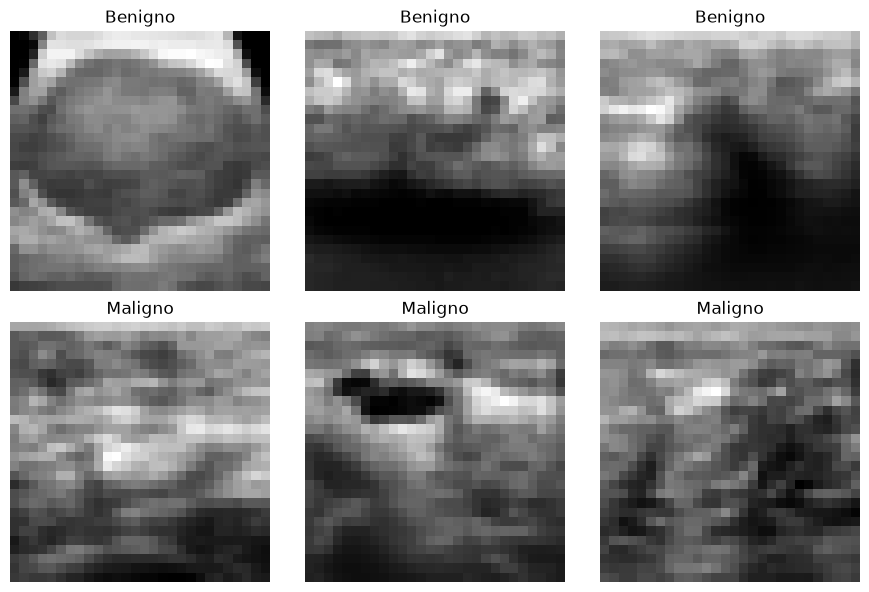

In [3]:
# TODO: Escribe tu código de visualización aquí

indices_benignos = np.where(y_train == 0)[0][:3]
indices_malignos = np.where(y_train == 1)[0][:3]

fig, axes = plt.subplots(2, 3, figsize=(9, 6))

for i in range(3):
    axes[0, i].imshow(X_train[indices_benignos[i]], cmap="gray")
    axes[0, i].set_title("Benigno")
    axes[0, i].axis("off")

    axes[1, i].imshow(X_train[indices_malignos[i]], cmap="gray")
    axes[1, i].set_title("Maligno")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

Al observar las imágenes benignas y malignas, se identifican diferencias en las formas, texturas e intensidades de los píxeles. Sin embargo, no se aprecia un patrón visual claro que permita distinguir ambas clases de manera confiable.

Debido a la baja resolución de las imágenes (28 × 28 píxeles), resulta difícil identificar características específicas a simple vista. Por ello, se utilizará PCA para reducir la dimensionalidad y posteriormente evaluar un modelo de clasificación.

## 2. Preprocesamiento y Vectorización
Para aplicar PCA o SVD estándar, necesitamos que cada imagen (una matriz 2D de 28x28) se convierta en un vector 1D (784 píxeles).

### Consigna 2: Vectorización y Centrado
1. Transforma `X_train` y `X_test` de dimensiones `(N, 28, 28)` a `(N, 784)`.
2. Calcula el **rostro (imagen) medio** del conjunto de entrenamiento y réstalo a todas las imágenes (tanto de train como de test) para centrar los datos.

In [4]:
# TODO: Escribe tu código de preprocesamiento y centrado aquí

# Aplanar las imágenes
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

# Normalizar los píxeles
X_train_norm = X_train_flat / 255.0
X_test_norm = X_test_flat / 255.0

# Calcular la media con los datos de entrenamiento
media = np.mean(X_train_norm, axis=0)

# Centrar los datos
X_train_centered = X_train_norm - media
X_test_centered = X_test_norm - media

print("Dimensiones:", X_train_centered.shape)
print("Media máxima absoluta:", np.abs(X_train_centered.mean(axis=0)).max())

Dimensiones: (546, 784)
Media máxima absoluta: 1.2422907635434788e-15


## 3. Reducción de Dimensionalidad con SVD / PCA
Ahora aplicaremos SVD a nuestra matriz de datos centrados para extraer los **Componentes Principales** (las "Eigen-imágenes").

### Consigna 3: Cálculo de SVD
1. Aplica SVD a la matriz de entrenamiento centrada para obtener `U`, `S` y `V^T`.
2. Grafica la varianza explicada acumulada y decide un valor de `r` (número de componentes) que conserve al menos el 90% de la energía/varianza.
3. Visualiza los primeros 5 componentes principales (Eigen-imágenes) redimensionándolos de nuevo a 28x28.

Dimensiones de U: (546, 546)
Dimensiones de S: (546,)
Dimensiones de Vt: (546, 784)

Componentes necesarios: 36
Varianza conservada: 90.11 %
Características originales: 784
Características reducidas: 36
Reducción de dimensionalidad: 95.41 %


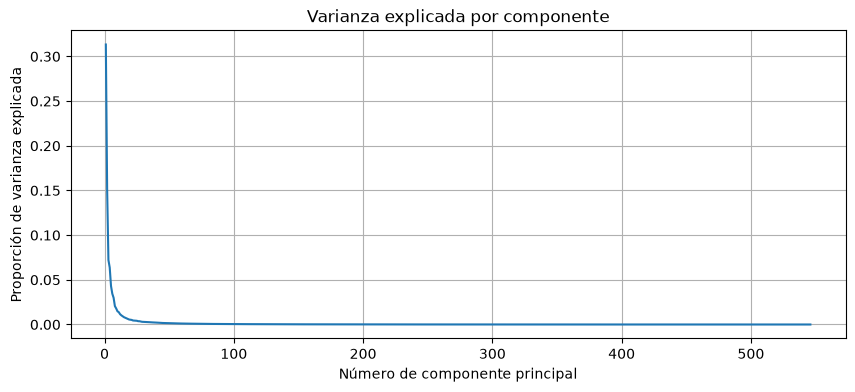

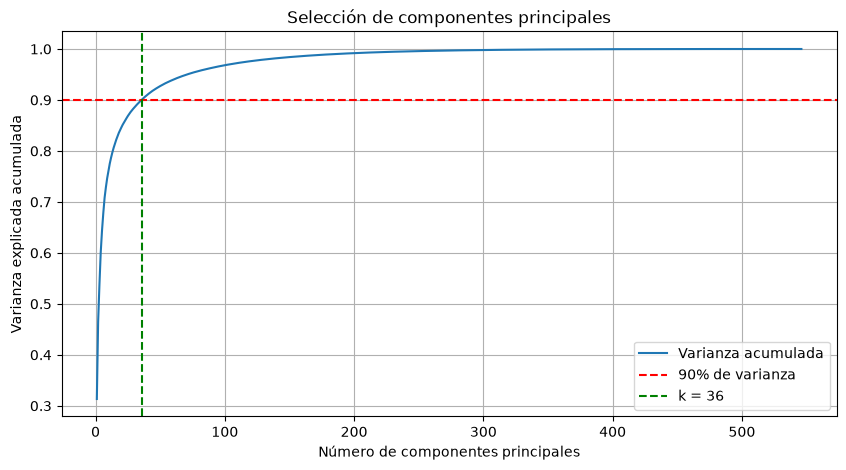

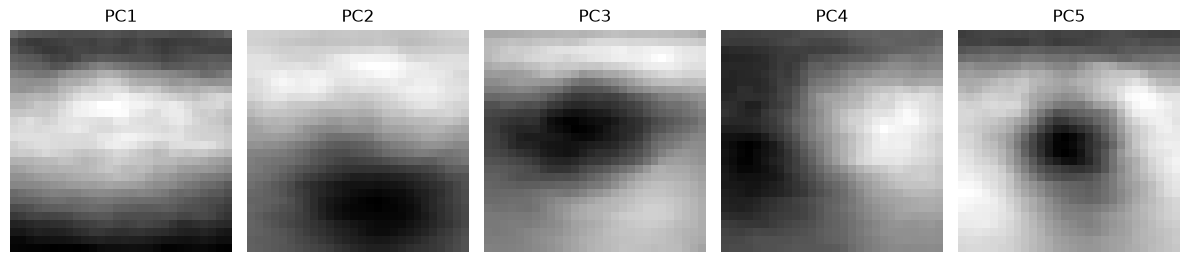

In [5]:
# TODO: Escribe tu código de SVD y visualización aquí

# 1. Calcular SVD
U, S, Vt = np.linalg.svd(X_train_centered, full_matrices=False)

print("Dimensiones de U:", U.shape)
print("Dimensiones de S:", S.shape)
print("Dimensiones de Vt:", Vt.shape)

# 2. Calcular la varianza explicada
varianza_explicada = S**2 / np.sum(S**2)
varianza_acumulada = np.cumsum(varianza_explicada)

# 3. Encontrar los componentes necesarios para conservar el 90%
k_90 = np.searchsorted(varianza_acumulada, 0.90) + 1

print("\nComponentes necesarios:", k_90)
print("Varianza conservada:", round(varianza_acumulada[k_90 - 1] * 100, 2), "%")

# 4. Calcular la reducción de dimensionalidad
caracteristicas_originales = X_train_centered.shape[1]
reduccion = (1 - k_90 / caracteristicas_originales) * 100

print("Características originales:", caracteristicas_originales)
print("Características reducidas:", k_90)
print("Reducción de dimensionalidad:", round(reduccion, 2), "%")

# 5. Graficar varianza explicada individual
plt.figure(figsize=(10, 4))
plt.plot(np.arange(1, len(S) + 1), varianza_explicada)
plt.xlabel("Número de componente principal")
plt.ylabel("Proporción de varianza explicada")
plt.title("Varianza explicada por componente")
plt.grid(True)
plt.show()

# 6. Graficar varianza explicada acumulada
plt.figure(figsize=(10, 5))

plt.plot(np.arange(1, len(S) + 1), varianza_acumulada,
         label="Varianza acumulada")

plt.axhline(y=0.90, color="red", linestyle="--",
            label="90% de varianza")

plt.axvline(x=k_90, color="green", linestyle="--",
            label=f"k = {k_90}")

plt.xlabel("Número de componentes principales")
plt.ylabel("Varianza explicada acumulada")
plt.title("Selección de componentes principales")
plt.legend()
plt.grid(True)
plt.show()

# 7. Visualizar las primeras 5 Eigen-imágenes
fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for i in range(5):
    imagen = Vt[i].reshape(28, 28)
    axes[i].imshow(imagen, cmap="gray")
    axes[i].set_title(f"PC{i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


## 4. Proyección y Clasificación
Una vez que tenemos la matriz de proyección (los primeros `r` componentes de `V^T` o equivalentemente usando Scikit-Learn `PCA`), proyectaremos los datos a un espacio de menor dimensión.

### Consigna 4: Clasificador Predictivo
1. Proyecta `X_train_centrado` y `X_test_centrado` sobre los primeros `r` componentes principales.
2. Entrena un clasificador simple, como **Regresión Logística** o **k-Nearest Neighbors (k-NN)**, usando las proyecciones de entrenamiento.
3. Evalúa el modelo en el conjunto de prueba usando `accuracy_score` y `classification_report`.
4. Prueba variar el número de componentes `r` (ej: 5, 20, 50) y describe cómo afecta el rendimiento.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# TODO: Escribe tu código de clasificación aquí

# 1. Proyectar los datos usando k_90 componentes
componentes = Vt[:k_90, :]

X_train_pca = X_train_centered @ componentes.T
X_test_pca = X_test_centered @ componentes.T

print("Dimensiones de entrenamiento:", X_train_pca.shape)
print("Dimensiones de prueba:", X_test_pca.shape)

# 2. Entrenar el modelo
modelo = LogisticRegression(max_iter=2000)
modelo.fit(X_train_pca, y_train)

# 3. Realizar predicciones
y_pred = modelo.predict(X_test_pca)

# 4. Evaluar los resultados
accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", round(accuracy, 4))
print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, zero_division=0))

# 5. Comparar diferentes cantidades de componentes
print("\nComparación de componentes:")

for r in [5, 20, k_90, 50]:
    componentes_r = Vt[:r, :]

    X_train_r = X_train_centered @ componentes_r.T
    X_test_r = X_test_centered @ componentes_r.T

    modelo_r = LogisticRegression(max_iter=2000)
    modelo_r.fit(X_train_r, y_train)

    predicciones = modelo_r.predict(X_test_r)
    accuracy_r = accuracy_score(y_test, predicciones)

    print(f"Componentes: {r} | Accuracy: {accuracy_r:.4f}")


Dimensiones de entrenamiento: (546, 36)
Dimensiones de prueba: (156, 36)

Accuracy: 0.7949

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.73      0.38      0.50        42
           1       0.81      0.95      0.87       114

    accuracy                           0.79       156
   macro avg       0.77      0.66      0.69       156
weighted avg       0.78      0.79      0.77       156


Comparación de componentes:
Componentes: 5 | Accuracy: 0.8013
Componentes: 20 | Accuracy: 0.7949
Componentes: 36 | Accuracy: 0.7949
Componentes: 50 | Accuracy: 0.7949


### Análisis de resultados de clasificación

Se entrenó un modelo de Regresión Logística utilizando las características obtenidas mediante PCA.

Con 36 componentes principales, suficientes para conservar al menos el 90 % de la varianza, se obtuvo un accuracy de **79,49 %**.

Al comparar diferentes cantidades de componentes, el mejor resultado se obtuvo con 5 componentes, alcanzando un accuracy del **80,13 %**. Con 20, 36 y 50 componentes, el accuracy fue del 79,49 %.

Estos resultados muestran que aumentar la cantidad de componentes principales no necesariamente mejora el rendimiento del clasificador.

Además, se observa una diferencia importante entre las clases: la clase 0 presentó un recall de 0,38, mientras que la clase 1 alcanzó un recall de 0,95. Esto indica que el modelo identifica mucho mejor los casos de la clase 1.

Por lo tanto, aunque PCA permite reducir considerablemente la dimensionalidad, es necesario evaluar otras métricas además del accuracy para determinar la calidad de la clasificación.

### Consigna Opcional (Bonus)
Implementa un clasificador que, en lugar de usar un modelo externo como Regresión Logística, utilice directamente la reconstrucción de PCA. Por ejemplo, midiendo el error de reconstrucción de una imagen de prueba usando los componentes calculados únicamente sobre imágenes benignas vs imágenes malignas.

In [7]:

# Bonus: Clasificación mediante error de reconstrucción PCA

# 1. Separar las imágenes de entrenamiento por clase
X_0 = X_train_norm[y_train == 0]
X_1 = X_train_norm[y_train == 1]

# 2. Calcular la media de cada clase
media_0 = X_0.mean(axis=0)
media_1 = X_1.mean(axis=0)

# 3. Centrar los datos de cada clase
X_0_centrado = X_0 - media_0
X_1_centrado = X_1 - media_1

# 4. Calcular SVD para cada clase
U0, S0, Vt0 = np.linalg.svd(X_0_centrado, full_matrices=False)
U1, S1, Vt1 = np.linalg.svd(X_1_centrado, full_matrices=False)

# 5. Seleccionar componentes principales
k = 5

componentes_0 = Vt0[:k]
componentes_1 = Vt1[:k]

# 6. Reconstruir las imágenes de prueba con cada PCA
X_test_0 = X_test_norm - media_0
X_test_1 = X_test_norm - media_1

reconstruccion_0 = (X_test_0 @ componentes_0.T) @ componentes_0 + media_0
reconstruccion_1 = (X_test_1 @ componentes_1.T) @ componentes_1 + media_1

# 7. Calcular el error de reconstrucción
error_0 = np.mean((X_test_norm - reconstruccion_0)**2, axis=1)
error_1 = np.mean((X_test_norm - reconstruccion_1)**2, axis=1)

# 8. Predecir la clase con menor error
y_pred_bonus = np.where(error_0 < error_1, 0, 1)

# 9. Evaluar el clasificador
print("Accuracy del bonus:", accuracy_score(y_test, y_pred_bonus))

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_bonus, zero_division=0))


Accuracy del bonus: 0.6794871794871795

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.44      0.69      0.54        42
           1       0.86      0.68      0.75       114

    accuracy                           0.68       156
   macro avg       0.65      0.68      0.65       156
weighted avg       0.74      0.68      0.70       156



### Conclusión del bonus: Clasificación por reconstrucción PCA

Se implementó un clasificador basado en el error de reconstrucción de PCA, utilizando cinco componentes principales para cada clase.

El modelo obtuvo un accuracy de **67,95 %**, inferior al 79,49 % alcanzado por Regresión Logística con 36 componentes principales.

Sin embargo, el clasificador por reconstrucción obtuvo un recall de 0,69 para la clase 0, superando el 0,38 obtenido por Regresión Logística. En contrapartida, el recall de la clase 1 disminuyó de 0,95 a 0,68.

Estos resultados muestran que el método de reconstrucción PCA consigue reconocer una mayor proporción de imágenes de la clase 0, pero presenta un rendimiento global inferior.

Se concluye que, para este conjunto de datos y con los parámetros utilizados, Regresión Logística ofrece un mejor accuracy general, mientras que la clasificación mediante reconstrucción PCA presenta un comportamiento más equilibrado en términos de recall entre ambas clases.